# 10 · Machine Learning and Cricket Predictions

Clean the data, explore it, build features, train models, test them honestly, and explain a prediction. The question is whether the models beat a plain baseline.

Needs: numpy, pandas, matplotlib, scikit-learn (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. The rule for this notebook

A model is only worth using if it beats a simple baseline on data it was not trained on. Every score below is measured with cross-validation or on a held-out test set, and each model is shown next to a baseline that always predicts the most common outcome.

All of the data is synthetic. A score here shows the code works. It tells you nothing about how well the same model would predict real cricket.

In [2]:
from pitchvision import ml
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

balls = pd.read_csv(DATA / "balls.csv")
print(len(balls), "rows")

1766 rows


## 2. Cleaning

The question: given where a delivery pitched, who bowled it and when, will the batter score off it?

Wides and no-balls are removed because the batter did not get a normal chance to score. Rows with no pitching point are removed because the main features need one. We print how many rows each step removes.

In [3]:
df, features, cleaning = ml.delivery_features(balls.to_dict("records"))
print(cleaning)
print("Missing values left in the model columns:", int(df[features].isna().sum().sum()))
df[features + ["target"]].describe().round(2)

{'rows_in': 1766, 'rows_used': 1702, 'dropped': 64}
Missing values left in the model columns: 0


,x,y,abs_x,is_spin,over,target
count,1702.00,1702.00,1702.00,1702.00,1702.00,1702.00
mean,0.16,6.14,0.25,0.37,8.67,0.58
std,0.26,1.98,0.18,0.48,5.51,0.49
min,-0.81,0.20,0.00,0.00,0.00,0.00
25%,-0.02,4.81,0.10,0.00,4.00,0.00
50%,0.16,6.15,0.21,0.00,8.00,1.00
75%,0.34,7.46,0.37,1.00,13.00,1.00
max,0.84,12.84,0.84,1.00,19.00,1.00


## 3. Exploring the data

The target is 1 when the ball was a dot or took a wicket, and 0 when the batter scored.

Dot or wicket on 58% of balls (1702 balls)


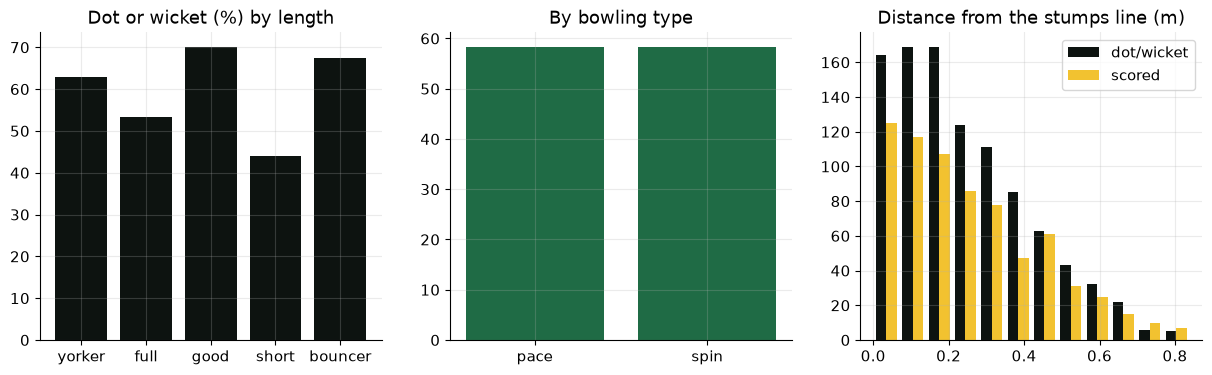

         mean  count
length              
yorker   0.63     27
full     0.53    769
good     0.70    603
short    0.44    263
bouncer  0.68     40


In [4]:
print(f"Dot or wicket on {df['target'].mean() * 100:.0f}% of balls ({len(df)} balls)")
df["length"] = df["y"].apply(__import__("pitchvision.pitchmap", fromlist=["x"]).classify_length)
by_len = df.groupby("length")["target"].agg(["mean", "count"]).reindex(["yorker", "full", "good", "short", "bouncer"]).dropna()
by_type = df.groupby("bowl_type")["target"].agg(["mean", "count"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(by_len.index, by_len["mean"] * 100, color=INK); axes[0].set_title("Dot or wicket (%) by length")
axes[1].bar(by_type.index, by_type["mean"] * 100, color=GREEN); axes[1].set_title("By bowling type")
axes[2].hist([df.loc[df.target == 1, "abs_x"], df.loc[df.target == 0, "abs_x"]], bins=12, label=["dot/wicket", "scored"], color=[INK, YELLOW])
axes[2].set_title("Distance from the stumps line (m)"); axes[2].legend(); plt.show()
print(by_len.round(2))

## 4. Features

| Feature | Meaning |
|---|---|
| x, y | where the ball pitched |
| abs_x | how far from the stumps line, either side |
| is_spin | 1 for a spinner |
| over | the over number |

abs_x is built from x because the distance from the stumps matters more than the side. A linear model cannot make that fold on its own.

In [5]:
X, y = df[features].to_numpy(float), df["target"].to_numpy(int)
print("Features:", features); print("Baseline accuracy (always predict the commoner outcome):", round(max(y.mean(), 1 - y.mean()), 3))

Features: ['x', 'y', 'abs_x', 'is_spin', 'over']
Baseline accuracy (always predict the commoner outcome): 0.583


## 5. Models and cross-validation

Five-fold cross-validation splits the data into five parts, trains on four and tests on the fifth, and repeats so every part is tested once. The spread across folds says how stable the score is. ROC-AUC measures how well the model ranks balls: 0.5 is no better than guessing and 1.0 is perfect.

,accuracy,accuracy sd,ROC-AUC,ROC-AUC sd
model,,,,
baseline,0.583,0.001,0.500,0.000
logistic regression,0.576,0.009,0.572,0.015
random forest,0.589,0.030,0.603,0.014
gradient boosting,0.608,0.023,0.611,0.014


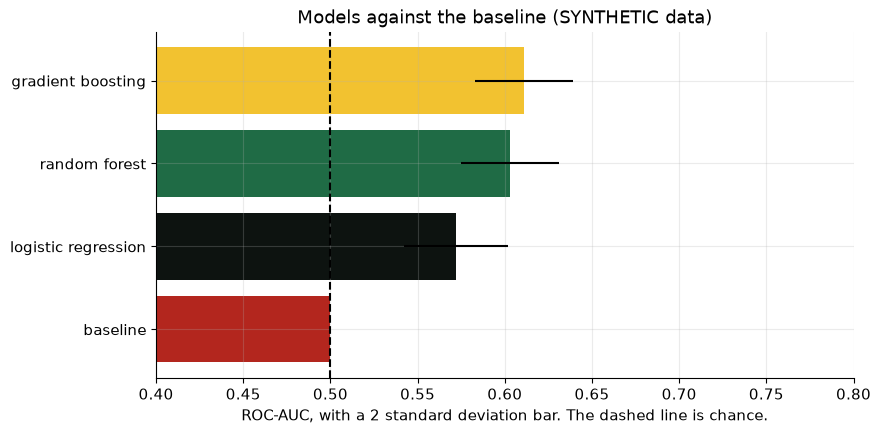

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {"baseline": DummyClassifier(strategy="most_frequent"),
          "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
          "random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=0),
          "gradient boosting": GradientBoostingClassifier(random_state=0)}
rows = []
for name, m in models.items():
    auc = cross_val_score(m, X, y, cv=cv, scoring="roc_auc"); acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    rows.append({"model": name, "accuracy": acc.mean(), "accuracy sd": acc.std(), "ROC-AUC": auc.mean(), "ROC-AUC sd": auc.std()})
results = pd.DataFrame(rows).set_index("model").round(3); display(results)

fig, ax = plt.subplots()
ax.barh(results.index, results["ROC-AUC"], xerr=2 * results["ROC-AUC sd"], color=[RED, INK, GREEN, YELLOW])
ax.axvline(0.5, color="black", ls="--"); ax.set_xlim(0.4, 0.8); ax.set_xlabel("ROC-AUC, with a 2 standard deviation bar. The dashed line is chance.")
ax.set_title("Models against the baseline (SYNTHETIC data)"); plt.show()

## 6. A held-out test set

Cross-validation chose between models, so a final check goes to data the choosing never touched.

Test ROC-AUC 0.573, test accuracy 0.577 on 426 balls


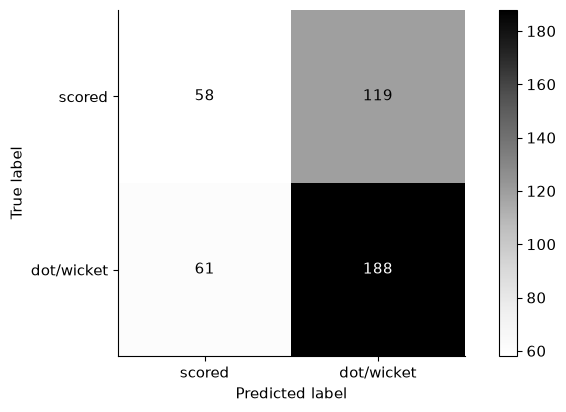

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)
best = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=0).fit(Xtr, ytr)
proba = best.predict_proba(Xte)[:, 1]
print(f"Test ROC-AUC {roc_auc_score(yte, proba):.3f}, test accuracy {(best.predict(Xte) == yte).mean():.3f} on {len(yte)} balls")
ConfusionMatrixDisplay(confusion_matrix(yte, best.predict(Xte)), display_labels=["scored", "dot/wicket"]).plot(cmap="Greys"); plt.grid(False); plt.show()

## 7. Feature importance

Permutation importance shuffles one feature at a time on the test set and measures how much the score drops. A large drop means the model relies on that feature.

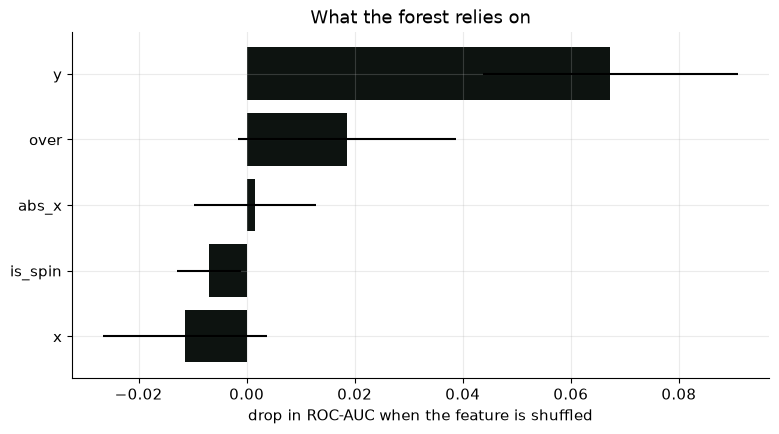

In [8]:
imp = permutation_importance(best, Xte, yte, n_repeats=20, random_state=0, scoring="roc_auc")
order = np.argsort(imp.importances_mean)
fig, ax = plt.subplots()
ax.barh(np.array(features)[order], imp.importances_mean[order], xerr=imp.importances_std[order], color=INK)
ax.set_xlabel("drop in ROC-AUC when the feature is shuffled"); ax.set_title("What the forest relies on"); plt.show()

## 8. Explaining one prediction

Partial dependence shows how the predicted chance changes as one feature moves with the others held at their typical values. For a single ball we can also print the inputs next to the prediction.

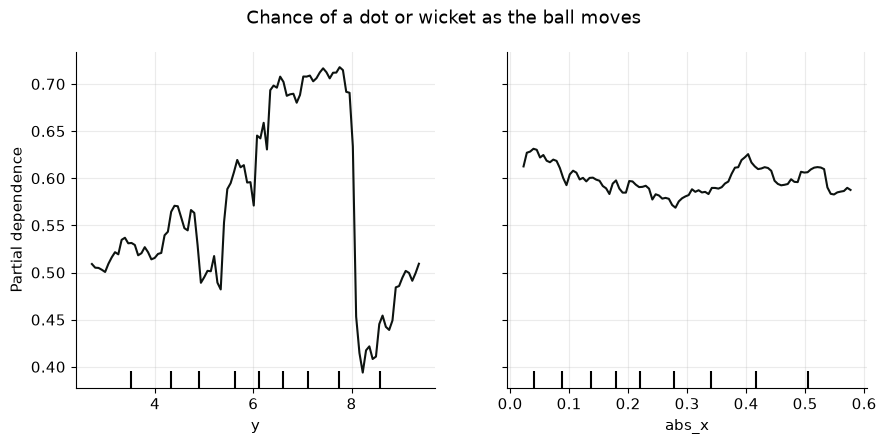

For a pace delivery pitching 7.0 m from the stumps and 15 cm outside off, the model estimates a 73% chance of a dot ball or wicket, against 58% for all recorded deliveries.
For a pace delivery pitching 1.0 m from the stumps and 15 cm outside off, the model estimates a 61% chance of a dot ball or wicket, against 58% for all recorded deliveries.
For a pace delivery pitching 7.0 m from the stumps and 90 cm outside off, the model estimates a 21% chance of a dot ball or wicket, against 58% for all recorded deliveries.
For a spin delivery pitching 5.0 m from the stumps and 15 cm outside off, the model estimates a 43% chance of a dot ball or wicket, against 58% for all recorded deliveries.

The model ranks deliveries better than chance (ROC-AUC above 0.5 by more than two standard deviations).
Trained and tested on SYNTHETIC data: these scores only show the pipeline works.


In [9]:
PartialDependenceDisplay.from_estimator(best, Xte, [features.index("y"), features.index("abs_x")], feature_names=features, line_kw={"color": INK})
plt.suptitle("Chance of a dot or wicket as the ball moves"); plt.tight_layout(); plt.show()

result = ml.train_dot_ball_model(balls.to_dict("records"), synthetic=True)
for case in [(0.15, 7.0, "pace"), (0.15, 1.0, "pace"), (0.9, 7.0, "pace"), (0.15, 5.0, "spin")]:
    e = ml.explain_delivery(result, case[0], case[1], case[2])
    print(e["explanation"])
print("\n" + result["conclusion"]); print(result["caveat"])

## 9. A second question: can a batter's next score be predicted?

The features are the average of the batter's last three scores and their career average before that innings. The baseline predicts the career average. The test uses time-ordered splits so the model never sees the future.

In [10]:
from pitchvision import scoring
lines = scoring.lines_from_balls(balls.to_dict("records"))
bat = pd.DataFrame([r for r in lines["batting"] if not r["player"].split()[0] in ("Northfield", "Riverside", "Hilltop", "Eastbrook")])
forecast = ml.batting_forecast(bat.to_dict("records"))
print(forecast.get("status"), "-", forecast.get("reason") or forecast["conclusion"])
if forecast["status"] == "ok":
    print(f"Model error {forecast['mae_model']:.2f} runs, career-average baseline {forecast['mae_baseline']:.2f} runs, over {forecast['rows']} innings")

ok - Recent form adds a little information beyond the career mean.
Model error 8.48 runs, career-average baseline 8.85 runs, over 43 innings


## 10. Trends

A trend is called up or down only when the 95% range for its slope excludes zero.

,readings,slope,low,high,direction
player,,,,,
Ethan Brooks,24,0.09,-0.04,0.23,no clear trend
Farhan Ali,24,0.09,-0.05,0.22,no clear trend
George Hill,24,0.15,0.04,0.26,up
Imran Khan,23,-0.04,-0.26,0.18,no clear trend
Jack Wood,24,0.18,0.04,0.32,up
Kabir Rao,24,0.18,0.03,0.32,up
Liam Shaw,24,0.05,-0.16,0.26,no clear trend
Milan Das,24,0.22,0.06,0.38,up


direction
no clear trend    4
up                4


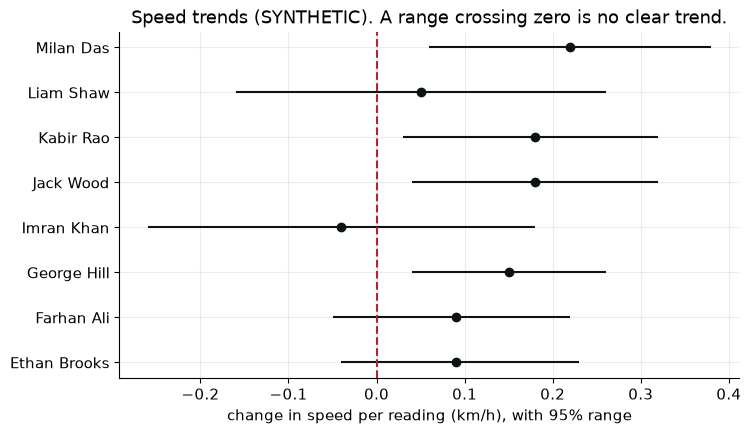

In [11]:
speeds = pd.read_csv(DATA / "speeds.csv", parse_dates=["date"]); speeds = speeds[speeds["source"] == "stopwatch"].dropna(subset=["kmh"])
rows = []
for name, g in speeds.sort_values("date").groupby("player"):
    t = ml.performance_trend(g["kmh"].tolist(), min_points=5)
    if t["status"] == "ok": rows.append({"player": name, "readings": t["n"], "slope": t["slope"], "low": t["ci_low"], "high": t["ci_high"], "direction": t["direction"]})
trend = pd.DataFrame(rows).set_index("player").round(2); display(trend)
print(trend["direction"].value_counts().to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(trend["slope"], range(len(trend)), xerr=[trend["slope"] - trend["low"], trend["high"] - trend["slope"]], fmt="o", color=INK, ecolor=INK)
ax.axvline(0, color=RED, ls="--"); ax.set_yticks(range(len(trend))); ax.set_yticklabels(trend.index)
ax.set_xlabel("change in speed per reading (km/h), with 95% range"); ax.set_title("Speed trends (SYNTHETIC). A range crossing zero is no clear trend."); plt.show()
results.to_csv(EXPORTS / "ml_model_scores.csv")

## 11. Grouping deliveries without labels

K-means groups deliveries by where they pitched. It has no right answer to be scored against, so the only claim is descriptive: these are the typical landing areas.

,cluster,x,y,count,length,line
0,0,0.05,4.02,147,full,stumps
1,1,0.27,8.24,201,short,off
2,2,-0.02,6.82,194,good,stumps
3,3,0.44,5.61,220,full,off


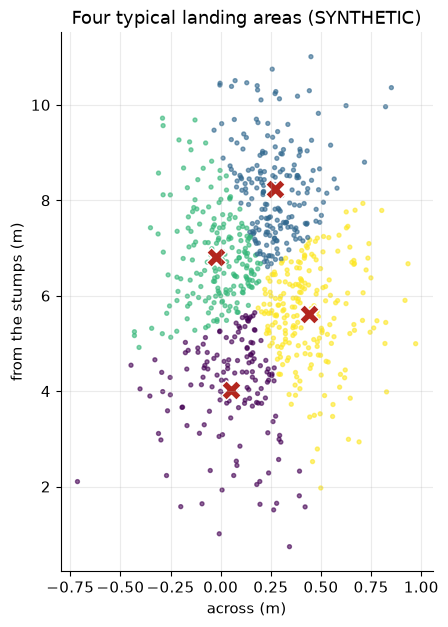

In [12]:
deliveries = pd.read_csv(DATA / "deliveries.csv").dropna(subset=["x", "y"])
cl = ml.cluster_deliveries(deliveries.to_dict("records"), k=4)
cdf = pd.DataFrame(cl["clusters"]); display(cdf.round(2))
fig, ax = plt.subplots(figsize=(4.8, 7))
ax.scatter(deliveries["x"], deliveries["y"], c=cl["labels"], cmap="viridis", s=8, alpha=0.6)
ax.scatter(cdf["x"], cdf["y"], marker="X", s=200, color=RED, edgecolor="white")
ax.set_xlabel("across (m)"); ax.set_ylabel("from the stumps (m)"); ax.set_title("Four typical landing areas (SYNTHETIC)"); plt.show()

## Summary

### Key findings
- Every model is shown next to a baseline, and every score comes from cross-validation or held-out data.
- Where a ball pitched predicts whether it is scored off only a little better than chance, which is what the generator built in.
- Recent form does not improve on a batter's career average in the forecast test, and most speed trends have a range that includes zero.

### Interpretation
On a school team's data the honest conclusion is usually that the models add little. That is a useful result: it says where not to spend effort.

### Limitations
- Synthetic data means a score proves nothing about real cricket.
- A season of a school team is a few thousand balls from a few players, which is small for machine learning.
- Balls are not independent: the same batter and bowler appear again and again, so cross-validation scores are somewhat optimistic.
- Features exclude what matters most: pace, swing, the batter's skill and the match situation.

### How this notebook connects to the application
`GET /api/ml/dot-ball-model` trains the same model on the opposition's balls in the database and returns the scores, baseline and feature importance. `ml.performance_trend` supplies the trend wording in the Progress tracker.